In [1]:
import numpy as np
import torch
import torch.nn as nn
import matplotlib.pyplot as plt
from pathlib import Path

from multiprocessing import Pool
import sys
from astropy.io import fits

In [2]:
name_fields = ['XMM', 'VVDS', 'GAMA09H', 'GAMA15H', 'WIDE12H', 'HECTOMAP']
number_patches = [8, 25, 23, 7, 26, 13]
_GALAXY_COUNTS_TOMOBIN_ = {}

for field, Npatch in zip(name_fields, number_patches):
    dats = [
        fits.getdata(f'~/HSCNG/data/real/hscy3_shape_chopped_{field}_{i}.fits')
        for i in range(Npatch)
    ]
    dat = np.concatenate(dats)
    _numbers = []
    for tomo_bin in [1, 2, 3, 4]:
        _numbers.append((dat['hsc_y3_zbin'] == tomo_bin).sum())
    _GALAXY_COUNTS_TOMOBIN_[field] = _numbers

# SBI
two step SBI:
- train NN from signals to (S8, Om)
- from S8(train), Om(train) and S8(real), Om(real) to posterior distribution

alternative plan
- train NN from each signal (C_ell, Peaks and Minima, etc.) to predict S8 Om individually - use S8(train, C_ell), Om(train, C_ell), S8(train, peaks), Om(train, peaks)... and S8(real), Om(real) to posterior distribution



## data C_ell
50 cosmologies * 50 realizations

2500 datas, each cosmology lets split ~20% as validation, which is 50 * 40 training + 50 * 10 testing

in the SBI paper, they first use optuna to optimize the hyperparameters, and then use 

In [3]:
cosmo_pars = np.loadtxt('/home/hedi/HSCNG/data/cosmo_params.txt', skiprows=1)
Om = cosmo_pars[:,1]
S8 = cosmo_pars[:,3]

In [4]:
Cl_tomo = []

for tomo in [1, 2, 3, 4]:
    Cl_cosmo_varied = []
    for cosmology_id in range(50):
        Cls = []
        for field in name_fields:
            dat = np.load(f'/lustre/work/gmarques/HSC_Y3_analysis_Gabriela/stats_cosmo_varied/power_spectrum/model{cosmology_id}_Clee_z{tomo}_{field}.npy')     # 50 realizations here
            Cls.append(dat)
        Cls = np.array(Cls)
        weights = [
            _GALAXY_COUNTS_TOMOBIN_[field][tomo - 1] for field in name_fields
        ]
        Cl_cosmo_varied.append(np.average(Cls, axis=0, weights=weights))

    Cl_tomo.append(np.array(Cl_cosmo_varied))
Cl_tomo = np.array(Cl_tomo)

In [5]:
def pre_process_C_ell(Cl_tomo, ell_min=100, ell_max=2000):
    """
    Preprocess the C_ell data by selecting a range of ell values and flattening the data.
    
    Parameters:
    Cl_tomo (numpy.ndarray): The input C_ell data with shape (tomobin, cosmology_id, realization, ell).
    ell_min (int): The minimum ell value to consider.
    ell_max (int): The maximum ell value to consider.
    
    Returns:
    numpy.ndarray: The preprocessed and flattened C_ell data.
    """
    import pymaster as nmt
    l_edges_log = np.unique(np.logspace(np.log10(80), np.log10(6500),15))
    binner = nmt.NmtBinFlat(l_edges_log[:-1], l_edges_log[1:]) #Namaster power spectrum binner 
    xx = binner.get_effective_ells()

    slice_ell = (xx >= ell_min) & (xx <= ell_max)          # apply a cut here.
    
    # Flatten the data across tomobin, cosmology_id, and realization dimensions
    Cl_concat = np.concat(Cl_tomo[:3, :, :, slice_ell], axis=2)
        # lets discard tomo bin 4 first, which is said to have "outliers"
    return Cl_concat

In [6]:
C_ell_concat = pre_process_C_ell(Cl_tomo, ell_min=300, ell_max=2000)

## data peaks & minima

In [7]:
peak_tomo = []

for tomo in [1, 2, 3, 4]:
    signal_cosmo_varied = []
    for cosmology_id in range(50):
        signals = []
        for field in name_fields:
            dat = np.load(f'/lustre/work/gmarques/HSC_Y3_analysis_Gabriela/stats_cosmo_varied/peaks/model{cosmology_id}_Peaks_z{tomo}_{field}.npy')     # 50 realizations here
            signals.append(dat)
        signals = np.array(signals)
        signal_cosmo_varied.append(np.sum(signals, axis=0))

    peak_tomo.append(np.array(signal_cosmo_varied))
peak_tomo = np.array(peak_tomo)

min_tomo = []

for tomo in [1, 2, 3, 4]:
    signal_cosmo_varied = []
    for cosmology_id in range(50):
        signals = []
        for field in name_fields:
            dat = np.load(f'/lustre/work/gmarques/HSC_Y3_analysis_Gabriela/stats_cosmo_varied/minima/model{cosmology_id}_Minima_z{tomo}_{field}.npy')     # 50 realizations here
            signals.append(dat)
        signals = np.array(signals)     # field, realization, kappa
        signal_cosmo_varied.append(np.sum(signals, axis=0))

    min_tomo.append(np.array(signal_cosmo_varied))
min_tomo = np.array(min_tomo)

In [8]:
def pre_process_peaks(peak_tomo, threshold=15):
    """
    Preprocess the peak data by applying a threshold and flattening the data across tomobin, cosmology_id, and realization dimensions.
    
    Parameters:
    - peak_tomo: numpy array of shape (tomobin, cosmology_id, realization, peak_value)
    - threshold: float, the threshold value to filter peaks
    
    Returns:
    - peak_concat: numpy array of shape (tomobin * cosmology_id * realization, filtered_peak_values)
    """
    # Apply threshold
    select_indice = (peak_tomo > threshold).any(axis=(0, 1, 2))     # it is safe, as far as I examined
    
    # Flatten the data across tomobin, cosmology_id, and realization dimensions
    peak_concat = np.concatenate(peak_tomo[:, :, :, select_indice], axis=2)
    
    return peak_concat

In [9]:
peak_concat = pre_process_peaks(peak_tomo, threshold=0)
min_concat = pre_process_peaks(min_tomo, threshold=0)

# peak_concat = pre_process_peaks(peak_tomo, threshold=15)
# min_concat = pre_process_peaks(min_tomo, threshold=15)

## data PDF

In [10]:
pdf_tomo = []

for tomo in [1, 2, 3, 4]:
    signal_cosmo_varied = []
    for cosmology_id in range(50):
        signals = []
        for field in name_fields:
            dat = np.load(f'/lustre/work/gmarques/HSC_Y3_analysis_Gabriela/stats_cosmo_varied/pdf/model{cosmology_id}_pdf_z{tomo}_{field}.npy')     # 50 realizations here
            signals.append(dat)
        signals = np.array(signals)
        weights = [
            _GALAXY_COUNTS_TOMOBIN_[field][tomo - 1] for field in name_fields
        ]
        signal_cosmo_varied.append(np.average(signals, axis=0, weights=weights))

    pdf_tomo.append(np.array(signal_cosmo_varied))
pdf_tomo = np.array(pdf_tomo)

In [11]:
# pdf_concat = np.concatenate(pdf_tomo[:, :, :, 3:], axis=2)      # cut the first 3 bins according to Thiele et al. 23
pdf_concat = np.concatenate(pdf_tomo[:, :, :, :], axis=2)

# data MFs

In [12]:
V0_tomo = []
V1_tomo = []
V2_tomo = []

for tomo in [1, 2, 3, 4]:
    signal_cosmo_varied = []
    for cosmology_id in range(50):
        signals = []
        for field in name_fields:
            dat = np.load(f'/lustre/work/gmarques/HSC_Y3_analysis_Gabriela/stats_cosmo_varied/MFs/model{cosmology_id}_V0_z{tomo}_{field}.npy')     # 50 realizations here
            signals.append(dat)
        signals = np.array(signals)
        weights = [
            _GALAXY_COUNTS_TOMOBIN_[field][tomo - 1] for field in name_fields
        ]
        signal_cosmo_varied.append(np.average(signals, axis=0, weights=weights))

    V0_tomo.append(np.array(signal_cosmo_varied))
V0_tomo = np.array(V0_tomo)

for tomo in [1, 2, 3, 4]:
    signal_cosmo_varied = []
    for cosmology_id in range(50):
        signals = []
        for field in name_fields:
            dat = np.load(f'/lustre/work/gmarques/HSC_Y3_analysis_Gabriela/stats_cosmo_varied/MFs/model{cosmology_id}_V1_z{tomo}_{field}.npy')     # 50 realizations here
            signals.append(dat)
        signals = np.array(signals)
        weights = [
            _GALAXY_COUNTS_TOMOBIN_[field][tomo - 1] for field in name_fields
        ]
        signal_cosmo_varied.append(np.average(signals, axis=0, weights=weights))

    V1_tomo.append(np.array(signal_cosmo_varied))
V1_tomo = np.array(V1_tomo)

for tomo in [1, 2, 3, 4]:
    signal_cosmo_varied = []
    for cosmology_id in range(50):
        signals = []
        for field in name_fields:
            dat = np.load(f'/lustre/work/gmarques/HSC_Y3_analysis_Gabriela/stats_cosmo_varied/MFs/model{cosmology_id}_V2_z{tomo}_{field}.npy')     # 50 realizations here
            signals.append(dat)
        signals = np.array(signals)
        weights = [
            _GALAXY_COUNTS_TOMOBIN_[field][tomo - 1] for field in name_fields
        ]
        signal_cosmo_varied.append(np.average(signals, axis=0, weights=weights))

    V2_tomo.append(np.array(signal_cosmo_varied))
V2_tomo = np.array(V2_tomo)

In [13]:
V0_concat = np.concatenate(V0_tomo, axis=2)
V1_concat = np.concatenate(V1_tomo, axis=2)
V2_concat = np.concatenate(V2_tomo, axis=2)

# concat data together

In [14]:
def train_test_split(
    data,
    label,
    test_size=0.2,
    leaveoutindex=None,
    random_state=42,
):  # for each cosmology, split realizations into train and test sets.

    rng = np.random.default_rng(random_state)

    n_cosmo, n_real, _ = data.shape
    n_train = int(n_real * (1 - test_size))

    label = np.asarray(label)

    X_train = []
    X_test = []

    theta_train = []
    theta_test = []

    for cosmo_id in range(n_cosmo):

        if leaveoutindex is not None and cosmo_id == leaveoutindex:
            continue

        # ONE realization split for this cosmology
        indices = rng.permutation(n_real)

        idx_train = indices[:n_train]
        idx_test = indices[n_train:]

        X_train.append(data[cosmo_id, idx_train, :])
        X_test.append(data[cosmo_id, idx_test, :])

        theta_c = np.atleast_1d(label[cosmo_id])

        theta_train.append(
            np.repeat(
                theta_c[None, :],
                len(idx_train),
                axis=0,
            )
        )

        theta_test.append(
            np.repeat(
                theta_c[None, :],
                len(idx_test),
                axis=0,
            )
        )

    return (
        np.concatenate(X_train),
        np.concatenate(X_test),
        np.concatenate(theta_train),
        np.concatenate(theta_test),
    )

In [15]:
signals_concat = np.concatenate([
    C_ell_concat, 
    peak_concat, 
    min_concat,
    pdf_concat,
    V0_concat,
    V1_concat,
    V2_concat
    ], axis=2)

print(signals_concat.shape)

(50, 50, 474)


In [16]:
dat_train, dat_test, label_train, label_test = train_test_split(signals_concat, label=np.c_[S8, Om], test_size=0.2, leaveoutindex=None, random_state=42)

In [17]:
print("data_train shape:", dat_train.shape)
print("data_test shape:", dat_test.shape)

data_train shape: (2000, 474)
data_test shape: (500, 474)


In [18]:
device = "cuda" if torch.cuda.is_available() else "cpu"
print("device:", device)

# ------------------------------------------------------------
# Standardize C_ell using TRAINING SET ONLY
# ------------------------------------------------------------
x_mean = dat_train.mean(axis=0)
x_std = dat_train.std(axis=0)

# protect against zero-variance bins
x_std[x_std == 0] = 1.0

x_train_np = (dat_train - x_mean) / x_std
x_test_np = (dat_test - x_mean) / x_std

x_train = torch.tensor(x_train_np, dtype=torch.float32)
x_test = torch.tensor(x_test_np, dtype=torch.float32)

# SBI theta must have shape (N, n_parameters)
theta_train = torch.tensor(
    label_train,
    dtype=torch.float32
)

theta_test = torch.tensor(
    label_test,
    dtype=torch.float32
)

print("x_train:", x_train.shape)
print("theta_train:", theta_train.shape)
print("x_test:", x_test.shape)
print("theta_test:", theta_test.shape)

device: cpu
x_train: torch.Size([2000, 474])
theta_train: torch.Size([2000, 2])
x_test: torch.Size([500, 474])
theta_test: torch.Size([500, 2])


# Step 1: train compression

In [19]:
class Embedding(nn.Module):
    def __init__(self, n_input, n_latent=8):
        super().__init__()

        self.net = nn.Sequential(            
            nn.Linear(n_input, 128),
            nn.GELU(),

            nn.Linear(128, 64),
            nn.GELU(),

            nn.Linear(64, 32),
            nn.GELU(),

            nn.Linear(32, n_latent),
        )

    def forward(self, x):
        return self.net(x)


embedding_net = Embedding(
    n_input=x_train.shape[1],
    n_latent=2,
)

print(embedding_net)

Embedding(
  (net): Sequential(
    (0): Linear(in_features=474, out_features=128, bias=True)
    (1): GELU(approximate='none')
    (2): Linear(in_features=128, out_features=64, bias=True)
    (3): GELU(approximate='none')
    (4): Linear(in_features=64, out_features=32, bias=True)
    (5): GELU(approximate='none')
    (6): Linear(in_features=32, out_features=2, bias=True)
  )
)


In [20]:
theta_mean = theta_train.mean(dim=0)
theta_std = theta_train.std(dim=0)

In [21]:
theta_train_normalized = (theta_train - theta_mean) / theta_std**0.5
theta_test_normalized = (theta_test - theta_mean) / theta_std**0.5

In [22]:
from torch.utils.data import DataLoader, TensorDataset
import copy

In [24]:
x_train.shape

torch.Size([2000, 474])

train x_train => theta_train_normalized, test with x_test, theta_test_normalized

### plan A

In [25]:
# Train embedding_net as a direct theta predictor
embedding_net = Embedding(
    n_input=x_train.shape[1],
    n_latent=2,
).to(device)
# x_train = x_train.to(device)
# theta_train = theta_train.to(device)
# x_test = x_test.to(device)
# theta_test = theta_test.to(device)

optimizer = torch.optim.Adam(embedding_net.parameters(), lr=5e-4)
num_epochs = 1000

loss_train = []
loss_test = []

test_epoch = 20

for epoch in range(num_epochs):
    embedding_net.train()
    optimizer.zero_grad()

    predict_train = embedding_net(x_train)
    diff = theta_train_normalized - predict_train
    # diff[:, 0] /= S8_range
    # diff[:, 1] /= Om_range
    loss = (diff ** 2).mean()      # loss defined as (Om - Om_pred)**2 + (S8 - S8_pred)**2, averaged over the batch.

    loss_train.append(loss.item())

    diff = theta_test_normalized - embedding_net(x_test)
    # diff[:, 0] /= S8_range
    # diff[:, 1] /= Om_range
    loss_test.append((diff ** 2).mean().item())

    if epoch >= test_epoch and np.abs(loss_train[-1] - np.mean(loss_train[-test_epoch:])) / loss_train[-1] < 1e-2:
        break

    loss.backward()
    optimizer.step()

    if (epoch + 1) % 50 == 0:
        print(f"Epoch {epoch + 1}/{num_epochs}, loss = {loss.item():.6f}")

embedding_net.eval()
# with torch.no_grad():
#     predict_train = embedding_net(x_train_device)

# print("Final training MSE:", torch.mean((theta_train_device - predict_train) ** 2).item())

Epoch 50/1000, loss = 0.024391
Epoch 100/1000, loss = 0.018401
Epoch 150/1000, loss = 0.013364


Embedding(
  (net): Sequential(
    (0): Linear(in_features=474, out_features=128, bias=True)
    (1): GELU(approximate='none')
    (2): Linear(in_features=128, out_features=64, bias=True)
    (3): GELU(approximate='none')
    (4): Linear(in_features=64, out_features=32, bias=True)
    (5): GELU(approximate='none')
    (6): Linear(in_features=32, out_features=2, bias=True)
  )
)

Final training MSE: 0.010895722545683384
Final test MSE: 0.029615404084324837


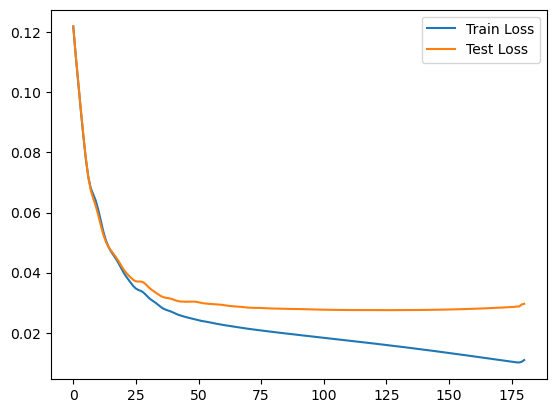

In [26]:
plt.plot(loss_train, label="Train Loss")
plt.plot(loss_test, label="Test Loss")

# plt.ylim(0, 0.1)

print("Final training MSE:", loss_train[-1])
print("Final test MSE:", loss_test[-1])

plt.legend()

### Plan B

In [27]:
model = Embedding(
    n_input=x_train.shape[1],
    n_latent=2,
).to(device)
optimizer = torch.optim.Adam(model.parameters(), lr=1e-4)

x_train = x_train.to(device)
theta_train_normalized = theta_train_normalized.to(device)
x_test = x_test.to(device)
theta_test_normalized = theta_test_normalized.to(device)

train_loader = DataLoader(
    TensorDataset(x_train, theta_train_normalized),
    batch_size=128,
    shuffle=True,
)


loss_train = []
loss_test = []

best_loss = np.inf
best_state = None
patience = 30
bad_epochs = 0

for epoch in range(500):

    # -----------------
    # training
    # -----------------
    model.train()

    for xb, yb in train_loader:
        xb = xb.to(device)
        yb = yb.to(device)

        optimizer.zero_grad()

        pred = model(xb)
        loss = ((pred - yb)**2).mean()

        loss.backward()
        optimizer.step()

    # -----------------
    # validation
    # -----------------
    model.eval()

    with torch.no_grad():
        val_pred = model(x_test)
        val_loss = ((val_pred - theta_test_normalized)**2).mean().item()
        loss_test.append(val_loss)

        pred = model(x_train)
        loss = ((pred - theta_train_normalized)**2).mean().item()
        loss_train.append(loss)

    if val_loss < best_loss:
        best_loss = val_loss
        best_state = copy.deepcopy(model.state_dict())
        bad_epochs = 0
    else:
        bad_epochs += 1

    if bad_epochs >= patience:
        break

model.load_state_dict(best_state)

<All keys matched successfully>

Text(0.5, 1.0, 'Training and Validation Loss\nlr=1e-4, batch_size=128, patience=30')

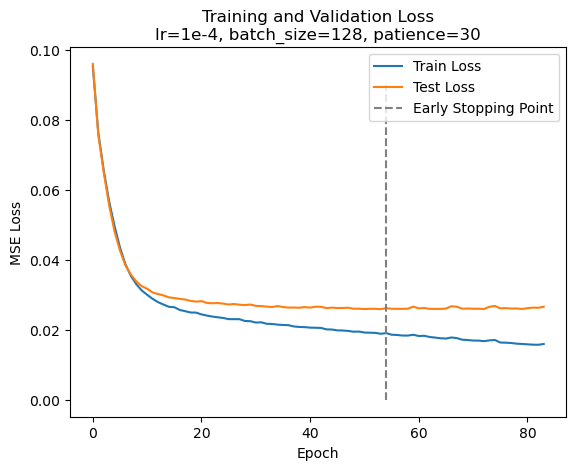

In [274]:
plt.plot(loss_train, label="Train Loss")
plt.plot(loss_test, label="Test Loss")

end_epoch = len(loss_train) - bad_epochs
plt.vlines(end_epoch, ymin=0, ymax=0.09, colors='grey', linestyles='dashed', label='Early Stopping Point')
plt.legend()
plt.xlabel("Epoch")
plt.ylabel("MSE Loss")
plt.title("Training and Validation Loss\nlr=1e-4, batch_size=128, patience=30")

## check NN compression

In [239]:
theta_train_normalized.shape

torch.Size([2000, 2])

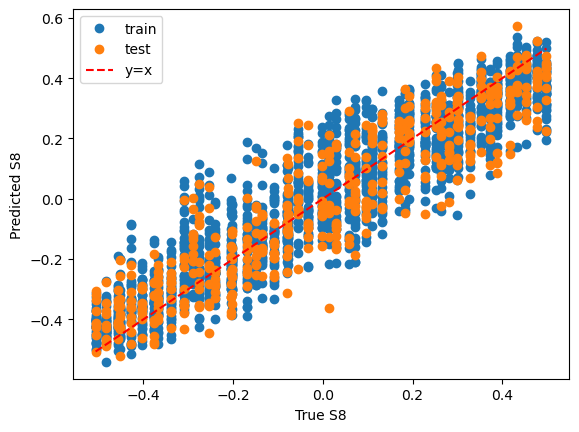

In [ ]:
S8_train = theta_train_normalized[:,0]
S8_pred = embedding_net(x_train)[:,0]

plt.plot(S8_train.cpu().numpy(), S8_pred.cpu().detach().numpy(), 'o', label='train')

S8_test = theta_test_normalized[:,0]
S8_pred = embedding_net(x_test)[:,0]

plt.plot(S8_test.cpu().numpy(), S8_pred.cpu().detach().numpy(), 'o', label='test')


limits = [
    S8_train.min().item(), S8_train.max().item()
]

plt.plot(limits, limits, 'r--', label='y=x')  # Add a reference line for y=x
plt.xlabel('True S8')
plt.ylabel('Predicted S8')
plt.legend()
plt.show()

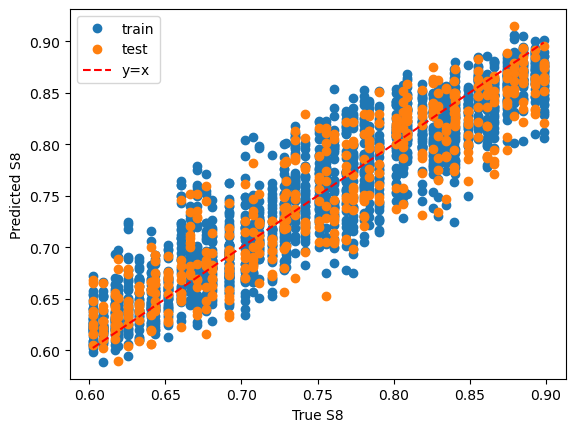

In [270]:
S8_train = theta_train_normalized[:,0] * theta_std[0]**0.5 + theta_mean[0]
S8_pred = model(x_train)[:,0] * theta_std[0]**0.5 + theta_mean[0]

plt.plot(S8_train.cpu().numpy(), S8_pred.cpu().detach().numpy(), 'o', label='train')



S8_test = theta_test_normalized[:,0] * theta_std[0]**0.5 + theta_mean[0]
S8_pred = model(x_test)[:,0] * theta_std[0]**0.5 + theta_mean[0]

plt.plot(S8_test.cpu().numpy(), S8_pred.cpu().detach().numpy(), 'o', label='test')


limits = [
    S8_train.min().item(), S8_train.max().item()
]

plt.plot(limits, limits, 'r--', label='y=x')  # Add a reference line for y=x
plt.xlabel('True S8')
plt.ylabel('Predicted S8')
plt.legend()
plt.show()

# step 2: SBI

In [249]:
pred_train = model(x_train).detach()
pred_test = model(x_test).detach()

In [251]:
from sbi.inference import SNPE
from sbi.utils import BoxUniform

# posterior_nn location differs slightly between sbi versions
try:
    from sbi.neural_nets import posterior_nn
except ImportError:
    from sbi.utils.get_nn_models import posterior_nn

/var/tmp/pbs.599713.idark/ipykernel_207114/1760096567.py:1: FutureWarning: `sbi.inference.SNPE` is deprecated since sbi v0.27.0 and will be removed in v0.28.0. Use `sbi.inference.NPE_C` instead.
  from sbi.inference import SNPE


In [252]:
prior = BoxUniform(
    low=torch.tensor([S8.min()-0.01, Om.min()-0.01], dtype=torch.float32),
    high=torch.tensor([S8.max()+0.01, Om.max()+0.01], dtype=torch.float32),
)

In [ ]:
density_estimator = posterior_nn(
    model="mdn",            # maybe try different model here?
    hidden_features=32,
    num_components=3,
)

density_estimator = posterior_nn(
    model="maf",
    hidden_features=32,
    num_components=3,
)

In [254]:
inference = SNPE(
    prior=prior,
    density_estimator=density_estimator,
    device=device,
)

inference = inference.append_simulations(
    theta_train,
    pred_train,
)

trained_density_estimator = inference.train(
    training_batch_size=128,
    learning_rate=1e-4,

    # sbi takes a fraction of x_train as its internal validation set
    validation_fraction=0.2,

    stop_after_epochs=15,
    max_num_epochs=500,

    show_train_summary=True,
)

summary = inference.summary

 Neural network successfully converged after 124 epochs.
        -------------------------
        ||||| ROUND 1 STATS |||||:
        -------------------------
        Epochs trained: 124
        Best validation performance: -3.5264
        -------------------------
        


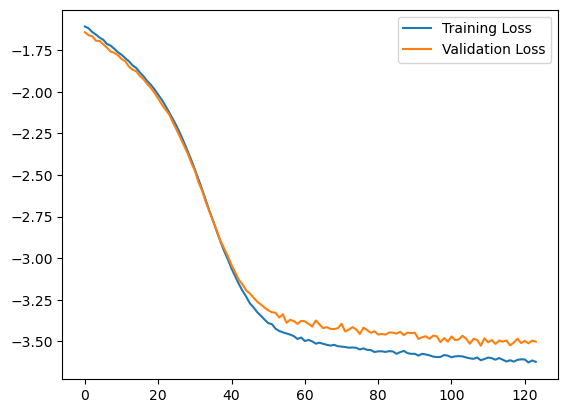

In [255]:
plt.plot(summary['training_loss'], label='Training Loss')
plt.plot(summary['validation_loss'], label='Validation Loss')
plt.legend()

In [256]:
posterior = inference.build_posterior(
    trained_density_estimator
)

In [281]:
import numpy as np
import pandas as pd

# Example: use the same bounds as your BoxUniform prior
prior_low = np.array([
    S8.min() - 0.01,
    Om.min() - 0.01,
])

prior_high = np.array([
    S8.max() + 0.01,
    Om.max() + 0.01,
])

acceptance_threshold = 0.5   # e.g. flag < 10%

low_acceptance = []

for i in range(len(pred_test)):

    samples_raw = posterior.sample(
        (20000,),
        x=pred_test[i],
        reject_outside_prior=False,
        show_progress_bars=False,
    ).cpu().detach().numpy()

    # samples_raw shape: (20000, 2)
    inside = np.all(
        (samples_raw >= prior_low) &
        (samples_raw <= prior_high),
        axis=1,
    )

    acceptance_rate = inside.mean()

    if acceptance_rate < acceptance_threshold:

        # assuming theta_test[:,0] = S8
        #          theta_test[:,1] = Om
        true_S8 = theta_test[i, 0].item()
        true_Om = theta_test[i, 1].item()

        median = np.median(samples_raw, axis=0)

        low_acceptance.append({
            "index": i,
            "S8_true": true_S8,
            "Om_true": true_Om,
            "acceptance_rate": acceptance_rate,
            "S8_raw_median": median[0],
            "Om_raw_median": median[1],
        })

        print(
            f"i={i:4d} | "
            f"accept={acceptance_rate:.4f} | "
            f"S8={true_S8:.4f}, Om={true_Om:.4f}"
        )

low_acceptance_df = pd.DataFrame(low_acceptance)

/var/tmp/pbs.599713.idark/ipykernel_207114/3019560174.py:21: UserWarning: 7.4% of samples drawn with reject_outside_prior=False lie outside the prior support. This may lead to incorrect inference.
  samples_raw = posterior.sample(
/var/tmp/pbs.599713.idark/ipykernel_207114/3019560174.py:21: UserWarning: 7.3% of samples drawn with reject_outside_prior=False lie outside the prior support. This may lead to incorrect inference.
  samples_raw = posterior.sample(
/var/tmp/pbs.599713.idark/ipykernel_207114/3019560174.py:21: UserWarning: 21.4% of samples drawn with reject_outside_prior=False lie outside the prior support. This may lead to incorrect inference.
  samples_raw = posterior.sample(
/var/tmp/pbs.599713.idark/ipykernel_207114/3019560174.py:21: UserWarning: 6.3% of samples drawn with reject_outside_prior=False lie outside the prior support. This may lead to incorrect inference.
  samples_raw = posterior.sample(
/var/tmp/pbs.599713.idark/ipykernel_207114/3019560174.py:21: UserWarning: 2

i=  35 | accept=0.2860 | S8=0.7351, Om=0.1072
i=  36 | accept=0.3043 | S8=0.7351, Om=0.1072


/var/tmp/pbs.599713.idark/ipykernel_207114/3019560174.py:21: UserWarning: 13.0% of samples drawn with reject_outside_prior=False lie outside the prior support. This may lead to incorrect inference.
  samples_raw = posterior.sample(
/var/tmp/pbs.599713.idark/ipykernel_207114/3019560174.py:21: UserWarning: 7.1% of samples drawn with reject_outside_prior=False lie outside the prior support. This may lead to incorrect inference.
  samples_raw = posterior.sample(
/var/tmp/pbs.599713.idark/ipykernel_207114/3019560174.py:21: UserWarning: 11.5% of samples drawn with reject_outside_prior=False lie outside the prior support. This may lead to incorrect inference.
  samples_raw = posterior.sample(
/var/tmp/pbs.599713.idark/ipykernel_207114/3019560174.py:21: UserWarning: 7.6% of samples drawn with reject_outside_prior=False lie outside the prior support. This may lead to incorrect inference.
  samples_raw = posterior.sample(
/var/tmp/pbs.599713.idark/ipykernel_207114/3019560174.py:21: UserWarning: 

i= 439 | accept=0.3941 | S8=0.8792, Om=0.5252


/var/tmp/pbs.599713.idark/ipykernel_207114/3019560174.py:21: UserWarning: 11.6% of samples drawn with reject_outside_prior=False lie outside the prior support. This may lead to incorrect inference.
  samples_raw = posterior.sample(
/var/tmp/pbs.599713.idark/ipykernel_207114/3019560174.py:21: UserWarning: 9.8% of samples drawn with reject_outside_prior=False lie outside the prior support. This may lead to incorrect inference.
  samples_raw = posterior.sample(
/var/tmp/pbs.599713.idark/ipykernel_207114/3019560174.py:21: UserWarning: 8.9% of samples drawn with reject_outside_prior=False lie outside the prior support. This may lead to incorrect inference.
  samples_raw = posterior.sample(
/var/tmp/pbs.599713.idark/ipykernel_207114/3019560174.py:21: UserWarning: 13.5% of samples drawn with reject_outside_prior=False lie outside the prior support. This may lead to incorrect inference.
  samples_raw = posterior.sample(
/var/tmp/pbs.599713.idark/ipykernel_207114/3019560174.py:21: UserWarning: 

In [308]:
np.argsort(bias_test)

array([ 79, 353, 455, 258, 235, 445, 489, 453, 456, 172, 280, 283, 121,
       476, 339, 381,  93, 458, 382, 419, 174, 232,   1, 332, 180, 350,
        60,   0, 277, 182, 237, 188, 338, 399,  34,  77, 330,  63, 152,
       359, 159, 475, 238, 253, 306, 438, 316,  28, 243, 275, 391, 239,
        90, 127, 195,  61, 250, 379, 341, 284, 287, 257, 413, 344, 375,
       236, 488, 271, 390,   3, 446, 126, 365, 184, 151, 337, 368, 120,
       380, 356, 155, 170, 129, 252, 334, 291, 187, 251, 240,  69, 367,
       474, 369, 185, 189, 221, 395, 422,  64, 231, 122, 175, 140, 333,
       480,  62, 428, 183,  75,  55, 314,  65,  21, 420, 163, 308, 123,
       312, 160, 249, 311, 125, 434, 230, 435, 142, 156, 374, 483, 303,
       124,  84, 396, 444, 366, 450, 449, 436, 273, 285, 254, 179, 448,
       161, 276, 425, 178, 269, 393, 279, 177, 248, 389, 309, 481, 198,
       383, 454, 360, 134, 300, 346, 397, 256, 181, 340, 355, 128, 158,
       432, 461, 267, 307, 466,  76, 137, 370, 234, 233, 297,  9

truth = [0.75539 0.1124 ]
raw median = [0.6539513  0.18956105]
raw 16/84 = [[0.62438757 0.14314363]
 [0.68356214 0.23645388]]
raw min = [0.5411008  0.02225131]
raw max = [0.83337885 0.61851656]


Text(0, 0.5, '$\\Omega_m$')

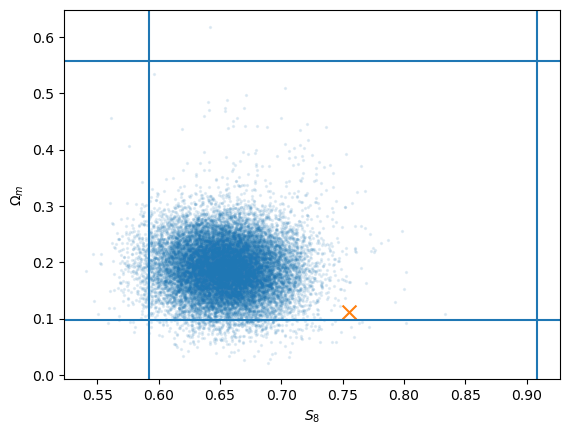

In [309]:
i = 79   # for example, one of your suspicious cases
x_obs = pred_test[i]

samples_raw = posterior.sample(
    (20000,),
    x=x_obs,
    reject_outside_prior=False,
    show_progress_bars=False,
).cpu().detach().numpy()

print("truth =", theta_test[i].numpy())

print("raw median =", np.median(samples_raw, axis=0))
print("raw 16/84 =", np.percentile(samples_raw, [16, 84], axis=0))

print("raw min =", samples_raw.min(axis=0))
print("raw max =", samples_raw.max(axis=0))

plt.scatter(
    samples_raw[:, 0],
    samples_raw[:, 1],
    s=2,
    alpha=0.1,
)

plt.axvline(S8.min()-0.01)
plt.axvline(S8.max()+0.01)

plt.axhline(Om.min()-0.01)
plt.axhline(Om.max()+0.01)

plt.scatter(
    theta_test[i, 0],
    theta_test[i, 1],
    marker="x",
    s=100,
)

plt.xlabel(r"$S_8$")
plt.ylabel(r"$\Omega_m$")

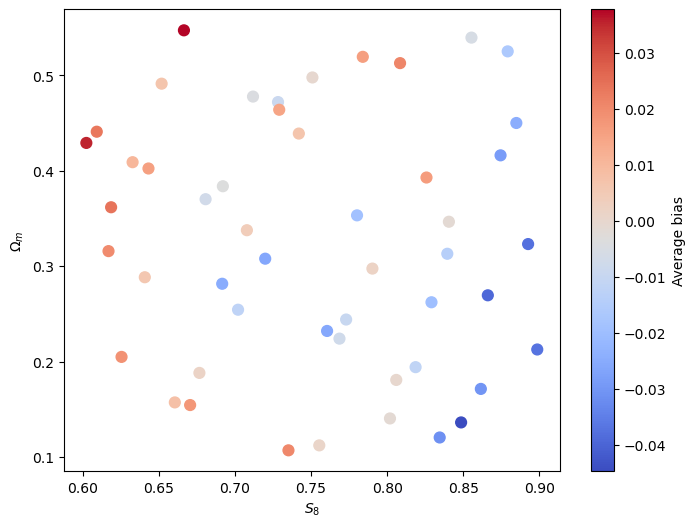

In [306]:
theta_np = theta_test.detach().cpu().numpy()
bias_np = np.asarray(bias_test)

# Group identical (S8, Om) values and average their biases
theta_unique, inverse = np.unique(theta_np, axis=0, return_inverse=True)
mean_bias = np.array([
    bias_np[inverse == group].mean()
    for group in range(len(theta_unique))
])

# Sort by S8, then Om
order = np.lexsort((theta_unique[:, 1], theta_unique[:, 0]))
S8_sorted = theta_unique[order, 0]
Om_sorted = theta_unique[order, 1]
bias_sorted = mean_bias[order]

fig = plt.figure(figsize=(8, 6))
ax = fig.add_subplot(111)

scatter = ax.scatter(
    S8_sorted,
    Om_sorted,
    c=bias_sorted,
    cmap="coolwarm",
    s=60,
)

ax.set_xlabel(r"$S_8$")
ax.set_ylabel(r"$\Omega_m$")
# ax.set_zlabel("Average bias")
fig.colorbar(scatter, ax=ax, label="Average bias")

plt.show()

In [258]:
bias_trained = []
pull_trained = []
for i in range(len(pred_train)):
    x_obs = pred_train[i]
    true_S8 = theta_train[i, 0]

    samples = posterior.sample(
        (10000,),
        x=x_obs,
        show_progress_bars=False,
    )

    samples_np = samples[:, 0].cpu().numpy()

    q16, q50, q84 = np.percentile(samples_np, [16, 50, 84])

    sigma = 0.5 * (q84 - q16)
    pull = (q50 - true_S8) / sigma
    bias_trained.append(q50 - true_S8)
    pull_trained.append(pull)

In [259]:
bias_test = []
pull_test = []
for i in range(len(pred_test)):
    x_obs = pred_test[i]
    true_S8 = theta_test[i, 0]

    samples = posterior.sample(
        (10000,),
        x=x_obs,
        show_progress_bars=False,
    )

    samples_np = samples[:, 0].cpu().numpy()

    q16, q50, q84 = np.percentile(samples_np, [16, 50, 84])

    sigma = 0.5 * (q84 - q16)
    pull = (q50 - true_S8) / sigma
    bias_test.append(q50 - true_S8)
    pull_test.append(pull)

In [260]:
print(np.mean(pull_trained), np.std(pull_trained))

print(np.mean(pull_test), np.std(pull_test))

-0.004017464 1.0277262
-0.1030948 1.1252011


In [261]:
cover68 = []
cover95 = []

for i in range(len(pred_test)):
    samples = posterior.sample(
        (5000,),
        x=pred_test[i],
        show_progress_bars=False,
    )[:, 0].cpu().numpy()

    q025, q16, q84, q975 = np.percentile(
        samples, [2.5, 16, 84, 97.5]
    )

    truth = theta_test[i, 0].item()

    cover68.append(q16 <= truth <= q84)
    cover95.append(q025 <= truth <= q975)

print("68% coverage =", np.mean(cover68))
print("95% coverage =", np.mean(cover95))

68% coverage = 0.606
95% coverage = 0.93


Text(0, 0.5, 'Pull (inferred - true) / sigma')

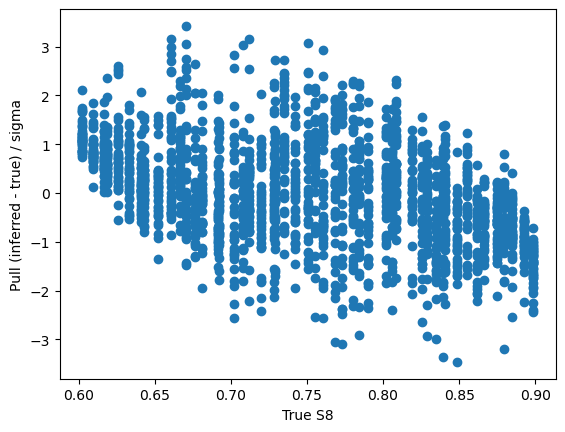

In [262]:
# plt.scatter(theta_test[:,0], pull_test)
plt.scatter(theta_train[:,0], pull_trained)
plt.xlabel("True S8")
plt.ylabel("Pull (inferred - true) / sigma")

In [264]:
constrained_S8 = []

for i in range(len(pred_test)):
    samples = posterior.sample(
        (5000,),
        x=pred_test[i],
        show_progress_bars=False,
    )[:, 0].cpu().numpy()

    q16, q50, q84 = np.percentile(
        samples, [16, 50, 84]
    )

    constrained_S8.append((q16, q50, q84))

Text(0, 0.5, 'Inferred $S_8$ with 68% CI')

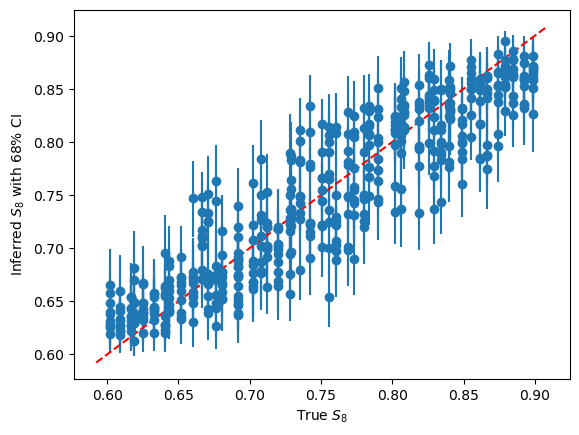

In [266]:
plt.errorbar(
    [theta_test[i, 0].item() for i in range(len(pred_test))],
    [q50 for q16, q50, q84 in constrained_S8],
    yerr=[
        [q50 - q16 for q16, q50, q84 in constrained_S8],
        [q84 - q50 for q16, q50, q84 in constrained_S8],
    ],
    fmt='o',
)
plt.plot(
    [S8.min()-0.01, S8.max()+0.01],
    [S8.min()-0.01, S8.max()+0.01],
    'r--',
)
plt.xlabel(r"True $S_8$")
plt.ylabel(r"Inferred $S_8$ with 68% CI")
